# CIN0209 Aprendizado de Máquina 1 | 2026.2 | Projeto prático

## Entrega 2: comparação das famílias de modelos com validação cruzada

**Dupla:** Ontje Simon Rath (osr) e Geraldo Camargo (gccmj)  <!-- TODO (dupla) -->

**Conjunto de dados:** [Default of Credit Card Clients — UCI Machine Learning Repository ](https://doi.org/10.24432/C55S3H)   <!-- TODO (dupla) -->

**Execução:** arquivos necessários (`am1_util.py`, divisão da E1 no Drive)

**Dados:** carregados pelo pacote ucimlrepo; o carregamento inicial
requer acesso à internet.

**Tempo de execução completa:** aproximadamente 23 minutos
no ambiente Colab utilizado. O tempo pode variar conforme os recursos disponíveis.

Prof. Leandro Maciel Almeida, CIn/UFPE. Prazo: 26/10, 23h59, pelo Classroom.

## 0. Instruções

**Como usar este modelo no Colab**

1. Abram este notebook no Colab e façam `Arquivo > Salvar uma cópia no Drive`. Trabalhem na cópia. **Pasta única da dupla:** um integrante cria a pasta `CIN0209_projeto` em *Meu Drive* e a compartilha com o outro como Editor; o outro usa *Adicionar atalho ao Drive* em *Meu Drive*, de modo que o caminho `MyDrive/Colab Notebooks/CIN0209_projeto` seja o mesmo para os dois. Dados, divisão, `test_log.csv` e tabelas ficam nessa pasta única. Só um integrante executa a célula do teste.
2. Carreguem o módulo de apoio `am1_util.py` de uma das três formas (a célula de carregamento abaixo tenta as três, nesta ordem):
   * já presente na pasta de trabalho do Colab (`/content`), enviado pelo painel *Arquivos* (upload);
   * salvo na pasta do projeto no Google Drive (variável `PASTA`), que é copiado para `/content`;
   * baixado da URL do kit (variável `URL_DO_KIT`; equivale a `!wget -q URL_DO_KIT -O am1_util.py`).
3. Executem o notebook do início ao fim (`Ambiente de execução > Reiniciar e executar tudo`; em versões recentes do Colab, `Reiniciar sessão e executar tudo`) antes de entregar. A entrega precisa rodar sem erros. Durante o desenvolvimento, a execução para de propósito na célula do teste (Seção 7) enquanto `TESTE_LIBERADO = False`; a execução final, que gera o PDF, é feita depois da liberação.
4. As células marcadas com `# TODO (dupla)` são decisões de vocês: preencham e **justifiquem em texto**. As **perguntas orientadoras** de cada seção não são para serem copiadas: respondam com a análise de vocês, apoiada nas tabelas e figuras.
5. O conjunto de **teste é usado uma única vez**, na Seção 7. A função `am.test_table` registra o uso em `test_log.csv` (na pasta do Drive) e recusa uma segunda avaliação. Toda escolha (hiperparâmetros, família campeã, versão mais simples ou não) acontece antes, por validação cruzada. A célula do teste só roda depois que `TESTE_LIBERADO` passa a `True` (célula logo após a declaração dos campeões); o registro de uso aparece impresso na Seção 7, inclusive no PDF.
6. Entrega no Classroom: link do notebook com acesso de leitura **e** cópia em PDF (`Arquivo > Imprimir > Salvar como PDF`), com as saídas visíveis.

**O que o módulo `am1_util` faz por vocês e o que é decisão da dupla.** O módulo traz funções prontas (pipelines das seis famílias, busca por validação cruzada, tabelas, curvas, regra de 1 erro padrão, avaliação única no teste). A dupla decide e justifica: a métrica principal, as grades de hiperparâmetros, a leitura das curvas e da lacuna treino-validação, a escolha da versão que vai ao teste e a interpretação dos resultados. Na arguição, cada integrante deve saber explicar o que cada função faz e por quê.

**Cronograma resumido do projeto**

| Data | Marco |
|---|---|
| 16/09 | Entrega 1 (realizada): exploração e baselines |
| 28/09 | Publicação da especificação do seminário e da rubrica |
| **26/10, 23h59** | **Entrega 2 (este notebook)**: link com acesso de leitura + PDF, pelo Classroom |
| Véspera de cada seminário | Envio do PDF dos slides |
| 23/11 e 25/11 | Seminários finais com arguição individual (metade das duplas em cada data; ordem sorteada e divulgada antes; presença obrigatória nas duas datas) |

Atraso: desconto de 1,0 ponto por dia, até 2 dias; depois, nota zero, salvo justificativa formal nos termos das normas da UFPE. Composição: P2 = 0,4 x NotaEntregas + 0,6 x NotaSeminário, com NotaEntregas = 0,4 x E1 + 0,6 x E2.

In [1]:
# Configuração do ambiente (pronta; ajustem apenas PASTA, se quiserem outro local no Drive)
import os
import shutil
import sys
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
USAR_DRIVE = True  # guarda divisão, registro do teste e tabelas no Drive (recomendado)

if IN_COLAB and USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA = "/content/drive/MyDrive/Colab Notebooks/CIN0209_projeto"  # pasta única da dupla (Seção 0, item 1)
else:
    PASTA = "."
os.makedirs(PASTA, exist_ok=True)

# Avisos de convergência da MLP são esperados quando a regularização é fraca
# (é justamente o regime de sobreajuste que a Seção 6 investiga). Para não
# poluir a saída, eles são silenciados aqui e nos processos paralelos.
os.environ["PYTHONWARNINGS"] = "ignore:Stochastic Optimizer"
warnings.filterwarnings("ignore", message="Stochastic Optimizer")

pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)
print("Colab:", IN_COLAB, "| pasta de trabalho:", os.path.abspath(PASTA))

Mounted at /content/drive
Colab: True | pasta de trabalho: /content/drive/MyDrive/Colab Notebooks/CIN0209_projeto


In [2]:
# Carregamento do módulo de apoio am1_util.py (pronto)
URL_DO_KIT = ""  # opcional: endereço de download do am1_util.py, se o professor o divulgar; o padrão é o upload ou a pasta do Drive

if not os.path.exists("am1_util.py"):
    no_drive = os.path.join(PASTA, "am1_util.py")
    if os.path.exists(no_drive):
        shutil.copy(no_drive, "am1_util.py")
    elif URL_DO_KIT.startswith("http"):
        urllib.request.urlretrieve(URL_DO_KIT, "am1_util.py")
    else:
        raise FileNotFoundError(
            "am1_util.py não encontrado: façam o upload no painel Arquivos, "
            "coloquem-no na PASTA do Drive ou definam URL_DO_KIT."
        )

import am1_util as am

print("am1_util versão", am.__version__)
print("Famílias:", am.FAMILIES)

am1_util versão 2026.2.0
Famílias: ('arvore', 'knn', 'naive_bayes', 'logistica', 'perceptron', 'mlp')


## 1. O problema e os dados (retomada da Entrega 1)

Retomem, em poucas linhas, a pergunta do projeto, a fonte e a licença dos dados, o significado do alvo e os principais achados da exploração da E1 que importam para a modelagem (balanceamento, faltantes, atributos categóricos de alta cardinalidade, escalas muito diferentes).

**Importante:** a preparação feita aqui deve produzir **exatamente** os mesmos `X` e `y` da E1, com as mesmas linhas e na mesma ordem; caso contrário, a divisão não é a mesma. Mantenham aqui apenas as operações por **linha ou coluna** que não aprendem nada dos dados (remover identificadores, duplicatas, registros inválidos, construir o alvo). Imputação, padronização e codificação agora ficam **dentro do Pipeline** (Seção 3) e não devem ser aplicadas à base inteira.

*Perguntas orientadoras:* Qual decisão prática o classificador apoia? Algum tratamento da E1 foi aplicado à base inteira antes da divisão (por exemplo, imputação, padronização, seleção de atributos pelo alvo ou reamostragem como SMOTE) e, portanto, precisa sair daqui?

*Resposta da dupla:*


O objetivo é investigar se informações demográficas e o histórico financeiro
de clientes permitem prever a inadimplência no pagamento do mês seguinte.

Trata-se de uma classificação binária: a variável alvo Y assume o valor 1
para inadimplência e 0 para ausência de inadimplência.

Utilizamos o conjunto Default of Credit Card Clients, disponibilizado por
I-Cheng Yeh no UCI Machine Learning Repository. A base original contém
30.000 registros e 23 atributos preditores.

Os atributos incluem:
- X1: limite de crédito;
- X2: sexo;
- X3: escolaridade;
- X4: estado civil;
- X5: idade;
- X6 a X11: situação dos pagamentos anteriores;
- X12 a X17: valores das faturas anteriores;
- X18 a X23: valores pagos anteriormente.

Na exploração da Entrega 1, observamos desbalanceamento da variável alvo:
aproximadamente 78% dos registros pertencem à classe 0 e 22% à classe 1.
Também identificamos diferenças de escala entre os atributos, ausência de
valores faltantes e 35 registros completamente duplicados.

Reproduzimos a preparação da Entrega 1 na mesma ordem: remoção das linhas
duplicadas e agrupamento dos códigos de escolaridade e estado civil.
Esses agrupamentos são regras fixas da preparação anterior.

A codificação one-hot e a padronização serão aprendidas exclusivamente
dentro dos Pipelines, no treino de cada fold da validação cruzada.

**Fonte:** Yeh, I. (2009). Default of Credit Card Clients.
UCI Machine Learning Repository. DOI: 10.24432/C55S3H.

**Licença:** Creative Commons Attribution 4.0 International — CC BY 4.0.

In [3]:
%pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo

# Conjunto de dados da Entrega 1
credit_data = fetch_ucirepo(id=350)

X_original = credit_data.data.features.copy()
y_original = credit_data.data.targets.copy()

df = pd.concat([X_original, y_original], axis=1)

# Preparação e ordem das operações da Entrega 1
df_limpo = df.drop_duplicates().copy()

df_limpo["X3"] = df_limpo["X3"].replace({
    0: 4,
    5: 4,
    6: 4
})

df_limpo["X4"] = df_limpo["X4"].replace({
    0: 3
})

X = df_limpo.drop(columns=["Y"]).copy()
y = df_limpo["Y"].copy()

# Preservamos a ordem e os índices das linhas
assert X.index.equals(y.index)
assert X.index.is_unique
assert len(df) == 30000, "A base carregada difere da base da E1."
assert len(df_limpo) == 29965, "A preparação difere da preparação da E1."
assert X.shape[1] == 23
assert set(y.unique()) == {0, 1}

print("Registros originais:", len(df))
print("Duplicatas removidas:", len(df) - len(df_limpo))
print("Registros após a preparação:", len(df_limpo))
print("Atributos preditores:", X.shape[1])

display(X.head())

Registros originais: 30000
Duplicatas removidas: 35
Registros após a preparação: 29965
Atributos preditores: 23


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [4]:
# Resumo dos dados (pronto)
print("Registros:", X.shape[0], "| atributos:", X.shape[1])
tipos = pd.DataFrame({
    "tipo": X.dtypes.astype(str),
    "faltantes (%)": (X.isna().mean() * 100).round(2),
    "valores distintos": X.nunique(),
})
display(tipos)
display(y.value_counts().to_frame("n").assign(proporcao=lambda t: t["n"] / t["n"].sum()))

Registros: 29965 | atributos: 23


,tipo,faltantes (%),valores distintos
X1,int64,0.0,81
X2,int64,0.0,2
X3,int64,0.0,4
X4,int64,0.0,3
X5,int64,0.0,56
X6,int64,0.0,11
X7,int64,0.0,11
X8,int64,0.0,11
X9,int64,0.0,11
X10,int64,0.0,10


,n,proporcao
Y,,
0,23335,0.7787
1,6630,0.2213


## 2. Mesma divisão e mesma semente da Entrega 1

Mantemos a semente 42 e reproduzimos exatamente as duas chamadas de
train_test_split da Entrega 1:

1. Separação de 70% para treino e 30% para um conjunto temporário.
2. Divisão do conjunto temporário em duas partes iguais:
   validação e teste.

As duas chamadas são estratificadas.

Utilizamos split_from_frames para registrar essa divisão no formato do kit,
pois a ordem das chamadas da nossa E1 difere da ordem assumida pela função
split_from_e1.

A divisão é salva em divisao_e1.json. Caso o arquivo já exista, verificamos
se seus índices coincidem com os índices reconstruídos.

O desenvolvimento da Entrega 2 é a união do treino e da validação da E1.
O conjunto de teste permanece separado e não participa das decisões.

In [5]:
from sklearn.model_selection import train_test_split

SEED = 42

# Reprodução EXATA das chamadas da Entrega 1.
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

split_reconstruido = am.split_from_frames(
    X,
    X_treino,
    X_validacao,
    X_teste,
    seed=SEED,
    y=y,
    notes="E1: 70% treino; restante dividido igualmente em validação e teste."
)

CAMINHO_DIVISAO = os.path.join(PASTA, "divisao_e1.json")

if os.path.exists(CAMINHO_DIVISAO):
    split = am.load_split(CAMINHO_DIVISAO)

    assert split["seed"] == SEED, "Semente salva diferente da E1."

    for parte in ("train", "val", "test"):
        np.testing.assert_array_equal(
            split[parte],
            split_reconstruido[parte],
            err_msg=f"A divisão salva difere da E1: {parte}."
        )

    print("Divisão salva conferida: índices idênticos à reconstrução da E1.")

else:
    split = am.save_split(
        CAMINHO_DIVISAO,
        split_reconstruido["train"],
        split_reconstruido["val"],
        split_reconstruido["test"],
        seed=SEED,
        y=y,
        notes="Divisão original da E1 reconstruída com as mesmas chamadas."
    )

    print("Divisão da E1 salva.")

# Tamanhos esperados após remover as 35 duplicatas.
TAMANHOS_E1 = {
    "treino": 20975,
    "validação": 4495,
    "teste": 4495
}

Divisão salva conferida: índices idênticos à reconstrução da E1.


In [6]:
X_dev, y_dev, X_test, y_test = am.development_set(X, y, split)

relatorio = am.split_report(y, split)
display(relatorio)

for conjunto, tamanho in TAMANHOS_E1.items():
    assert int(relatorio.loc[conjunto, "n"]) == tamanho

# Conferência dos índices e da ordem do teste.
pd.testing.assert_frame_equal(X_test, X_teste)
pd.testing.assert_series_equal(y_test, y_teste)

# Nenhuma sobreposição entre desenvolvimento e teste.
assert set(X_dev.index).isdisjoint(set(X_test.index))

# Todas as linhas da base preparada estão contempladas.
assert len(X_dev) + len(X_test) == len(X)
assert len(X_dev) == 25470
assert len(X_test) == 4495

print("Desenvolvimento:", X_dev.shape)
print("Teste reservado:", X_test.shape)
print("Divisão original preservada. Nenhum modelo foi avaliado no teste.")

,n,fracao,prop_0,prop_1
conjunto,,,,
treino,20975,0.70,0.7787,0.2213
validação,4495,0.15,0.7786,0.2214
desenvolvimento,25470,0.85,0.7787,0.2213
teste,4495,0.15,0.7789,0.2211
total,29965,1.00,0.7787,0.2213


Desenvolvimento: (25470, 23)
Teste reservado: (4495, 23)
Divisão original preservada. Nenhum modelo foi avaliado no teste.


### Mudanças em relação à Entrega 1

Mantivemos o mesmo conjunto de dados e a preparação da Entrega 1:
remoção de 35 registros duplicados, agrupamento dos códigos 0, 5 e 6
de X3 na categoria 4 e agrupamento do código 0 de X4 na categoria 3.
A base preparada contém 29.965 registros e 23 atributos preditores.

Preservamos a semente 42 e as duas chamadas originais de
train_test_split, ambas estratificadas. Os tamanhos são:
20.975 registros de treino, 4.495 de validação e 4.495 de teste.
Na Entrega 2, treino e validação formam o desenvolvimento,
com 25.470 registros.

Na E1, a codificação e a padronização já eram ajustadas apenas
no conjunto de treino e aplicadas à validação e ao teste.
Na E2, essas etapas passaram a integrar os Pipelines para que
sejam ajustadas separadamente no treino de cada fold.

Substituímos a seleção por uma única partição de validação
pela validação cruzada estratificada com cinco folds.
A métrica principal passou de acurácia para acurácia balanceada,
justificada pelo desbalanceamento das classes observado na E1.

Ampliamos a comparação para as seis famílias obrigatórias:
árvore de decisão, kNN, Naive Bayes, regressão logística,
Perceptron e MLP. Acrescentamos o LightGBM como extensão bônus.
O LVQ utilizado na E1 não foi incluído nesta entrega.

O estudo de overfitting foi ampliado com lacunas treino-validação
por família e curvas de complexidade com a regra de 1 erro padrão.

O teste já foi utilizado na E1 como diagnóstico preliminar.
Reconhecemos esse uso como limitação; os resultados de teste da E1
não orientaram as decisões da E2.

## 3. Protocolo: validação cruzada no desenvolvimento, sem vazamento

**Por que validação cruzada.** Na E1, as escolhas foram feitas com uma única partição de validação; o resultado dependia de quais registros caíram nela. Com a validação cruzada estratificada (k = 5, semente da dupla), cada registro do desenvolvimento é usado como validação exatamente uma vez, e obtemos a média e a variabilidade entre folds. Os mesmos folds são usados para todas as famílias, o que torna a comparação pareada.

**Por que Pipeline.** Imputação, padronização e codificação aprendem estatísticas dos dados (medianas, médias, desvios, categorias). Se forem ajustadas no desenvolvimento inteiro **antes** da validação cruzada, a parte de validação de cada fold influencia a transformação aplicada a ela mesma: isso é **vazamento**, e as estimativas ficam otimistas. Exemplo: ao padronizar com `StandardScaler().fit(X_dev)` e depois rodar a validação cruzada, a média e o desvio usados no fold 1 incluem os registros de validação do fold 1. Com `Pipeline([("prep", ...), ("model", ...)])`, o `fit` do pré-processamento acontece apenas na parte de treino de cada fold, como aconteceria com dados realmente novos.

**Padronização onde precisa.** kNN, regressão logística, Perceptron e MLP dependem da escala; a árvore não. No Naive Bayes Gaussiano a decisão é invariante à escala de cada atributo, exceto pela suavização de variância (`var_smoothing`), proporcional à maior variância: por isso o módulo também padroniza para o NB. Vejam `help(am.preprocessor)`.

**Limitação a declarar.** Na E1, o teste já foi consultado uma vez como diagnóstico preliminar. Nesta entrega ele volta a ser usado apenas no fim; nas conclusões e limitações (Seção 9), esse uso anterior deve ser mencionado como limitação.

**Métrica principal.** A busca precisa de **uma** métrica para escolher hiperparâmetros (`SCORING`). As demais (acurácia, acurácia balanceada, F1 macro, AUC, log loss) aparecem na tabela final.

*Perguntas orientadoras:* Considerando o balanceamento das classes e o custo de cada tipo de erro no problema de vocês, qual métrica representa melhor o objetivo? Por que a acurácia simples pode enganar? Qual é o custo computacional esperado da busca, dado o tamanho do desenvolvimento?

*Métrica principal escolhida e justificativa:*

Utilizamos a acurácia balanceada como métrica principal.

Como a classe de clientes sem inadimplência é majoritária, a acurácia simples
pode favorecer modelos que identificam bem essa classe, mas identificam poucos
clientes inadimplentes.

A acurácia balanceada corresponde à média do recall das duas classes,
atribuindo o mesmo peso a cada uma.

Todas as famílias utilizarão as mesmas cinco partições estratificadas,
com embaralhamento e semente 42. As decisões serão tomadas exclusivamente
no desenvolvimento.

Inicialmente, utilizaremos todo o desenvolvimento, sem subamostragem.
O custo computacional será registrado pelo tempo das buscas.

As colunas X2, X3 e X4 serão tratadas explicitamente como categóricas,
apesar de estarem armazenadas como números inteiros. As demais colunas
serão tratadas como numéricas, mantendo a representação adotada na E1.

In [7]:
# TODO (dupla): métrica principal (uma só) e configuração da validação cruzada.
SCORING = "balanced_accuracy"  # TODO: ex. "balanced_accuracy", "f1_macro", "roc_auc" (binário), "roc_auc_ovr", "neg_log_loss"
N_FOLDS = 5
N_JOBS = -1  # todos os núcleos disponíveis (o Colab gratuito tem 2)

# Subamostragem do desenvolvimento, SÓ se a base for muito grande (decisão a priori e justificada).
# O teste nunca é subamostrado. None = usar o desenvolvimento inteiro.
N_MAX_DEV = None  # TODO (opcional): ex. 20000 para bases com centenas de milhares de linhas

COLUNAS_CATEGORICAS = ["X2", "X3", "X4"]
COLUNAS_NUMERICAS = [
    coluna for coluna in X.columns
    if coluna not in COLUNAS_CATEGORICAS
]

PREP_KWARGS = {
    "categorical": COLUNAS_CATEGORICAS,
    "numeric": COLUNAS_NUMERICAS
}

print("Métrica principal:", SCORING)
print("Semente:", SEED)
print("Colunas categóricas:", COLUNAS_CATEGORICAS)
print("Número de colunas numéricas:", len(COLUNAS_NUMERICAS))

Métrica principal: balanced_accuracy
Semente: 42
Colunas categóricas: ['X2', 'X3', 'X4']
Número de colunas numéricas: 20


In [8]:
# Validação cruzada comum a todas as famílias (pronto)
X_dev_completo, y_dev_completo = X_dev, y_dev  # desenvolvimento inteiro, guardado para o reajuste final
if N_MAX_DEV is not None:
    X_dev, y_dev = am.stratified_subsample(X_dev, y_dev, N_MAX_DEV, SEED)
    print("Desenvolvimento subamostrado para", len(y_dev), "registros (mesma subamostra para todas as famílias).")

cv = am.make_cv(SEED, n_splits=N_FOLDS)
print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## 4. Busca de hiperparâmetros por validação cruzada nas seis famílias

Famílias obrigatórias: árvore de decisão, kNN, Naive Bayes (Gaussiano), regressão logística, Perceptron (separador linear, calibrado para produzir probabilidades) e MLP. As grades de `am.SUGGESTED_GRIDS` são um ponto de partida: adaptem ao problema de vocês e justifiquem.

*Perguntas orientadoras:* O melhor valor ficou na borda da grade? Se sim, a grade deve ser ampliada nessa direção. Que hiperparâmetro controla a complexidade de cada família? Por que a MLP é avaliada sem parada antecipada (`early_stopping=False`)? Por que o Perceptron precisa de calibração para entrar na tabela de AUC e log loss? O tempo de cada busca é compatível com o tamanho da base?

In [9]:
# Grades sugeridas (pronto: apenas exibe)
for familia in am.FAMILIES:
    print(f"{familia:12s}", am.SUGGESTED_GRIDS[familia])

arvore       {'model__max_depth': [3, 5, 8, 12, None], 'model__min_samples_leaf': [1, 5, 20, 50]}
knn          {'model__n_neighbors': [3, 5, 11, 21, 41], 'model__weights': ['uniform', 'distance']}
naive_bayes  {'model__var_smoothing': [1e-09, 1e-07, 1e-05, 0.001, 0.1]}
logistica    {'model__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
perceptron   [{'model__estimator__penalty': [None]}, {'model__estimator__penalty': ['l2'], 'model__estimator__alpha': [1e-05, 0.0001, 0.001, 0.01]}]
mlp          {'model__hidden_layer_sizes': [(32,), (64,)], 'model__alpha': [0.0001, 0.01, 0.1, 1.0]}


In [10]:
import copy

grades = copy.deepcopy(am.SUGGESTED_GRIDS)

# Árvore: explorar profundidades menores e folhas maiores.
grades["arvore"] = {
    "model__max_depth": [1, 2, 3, 5, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 20, 50, 100, 200, 400, 800, 1600]
}

# Naive Bayes: ampliar a suavização acima de 0.1.
grades["naive_bayes"] = {
    "model__var_smoothing": [
        1e-9, 1e-7, 1e-5, 1e-3, 0.1, 1.0, 10.0
    ]
}

# Regressão logística: explorar regularização mais fraca.
grades["logistica"] = {
    "model__C": [
        0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0
    ]
}

# Perceptron: ampliar a faixa para valores menores de alpha.
grades["perceptron"] = [
    {
        "model__estimator__penalty": [None]
    },
    {
        "model__estimator__penalty": ["l2"],
        "model__estimator__alpha": [
            1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2
        ]
    }
]

# MLP: incluir uma camada oculta menor.
grades["mlp"] = {
    "model__hidden_layer_sizes": [(16,), (32,), (64,)],
    "model__alpha": [1e-4, 1e-2, 1e-1, 1.0]
}

# kNN: manter a grade inicial.
for familia, grade in grades.items():
    print(f"\n{familia}:")
    print(grade)


arvore:
{'model__max_depth': [1, 2, 3, 5, 8, 12, None], 'model__min_samples_leaf': [1, 5, 20, 50, 100, 200, 400, 800, 1600]}

knn:
{'model__n_neighbors': [3, 5, 11, 21, 41], 'model__weights': ['uniform', 'distance']}

naive_bayes:
{'model__var_smoothing': [1e-09, 1e-07, 1e-05, 0.001, 0.1, 1.0, 10.0]}

logistica:
{'model__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]}

perceptron:
[{'model__estimator__penalty': [None]}, {'model__estimator__penalty': ['l2'], 'model__estimator__alpha': [1e-07, 1e-06, 1e-05, 0.0001, 0.001, 0.01]}]

mlp:
{'model__hidden_layer_sizes': [(16,), (32,), (64,)], 'model__alpha': [0.0001, 0.01, 0.1, 1.0]}


*Justificativa das grades:* Utilizamos inicialmente as grades sugeridas pelo kit e examinamos os
hiperparâmetros selecionados pela validação cruzada.

Na árvore, a melhor configuração apresentou max_depth=3 e
min_samples_leaf=50, nas bordas das faixas investigadas. Por isso,
incluímos profundidades menores e valores maiores de min_samples_leaf.

No Naive Bayes, ampliamos var_smoothing acima de 0.1. Na regressão
logística, ampliamos C acima de 100. No Perceptron, incluímos valores
de alpha menores que 1e-5.

Na MLP, incluímos uma camada oculta com 16 unidades para verificar
uma arquitetura menor que a melhor arquitetura inicial, de 32 unidades.

No kNN, mantivemos a grade, pois o melhor número de vizinhos, 21,
estava no interior da faixa investigada.

Todas essas decisões se baseiam exclusivamente na validação cruzada
no desenvolvimento. O conjunto de teste permanece reservado.

Na primeira ampliação, a árvore selecionou min_samples_leaf=200,
novamente no limite superior. Por isso, estendemos essa faixa para
incluir 400, 800 e 1600 exemplos por folha, mantendo os mesmos folds,
a métrica e o pré-processamento.

Após a segunda ampliação da árvore, a melhor configuração foi
max_depth=5 e min_samples_leaf=400, ambos no interior das faixas
investigadas. A acurácia balanceada média foi de 0,6615.
As ampliações das outras famílias mantiveram as configurações
anteriormente selecionadas.

In [11]:
# Busca por validação cruzada em todas as famílias (pronto)
buscas = {}

for familia in am.FAMILIES:
    print(f"\nIniciando busca: {familia}")

    buscas[familia] = am.cv_search(
        familia,
        X_dev,
        y_dev,
        grid=grades[familia],
        cv=cv,
        scoring=SCORING,
        n_jobs=N_JOBS,
        seed=SEED,
        prep_kwargs=PREP_KWARGS
    )

    print(
        f"{familia}: "
        f"melhor {SCORING} = {buscas[familia].best_score_:.4f}; "
        f"tempo = {buscas[familia].elapsed_:.1f} s"
    )


Iniciando busca: arvore
arvore: melhor balanced_accuracy = 0.6615; tempo = 156.7 s

Iniciando busca: knn
knn: melhor balanced_accuracy = 0.6435; tempo = 185.1 s

Iniciando busca: naive_bayes
naive_bayes: melhor balanced_accuracy = 0.6937; tempo = 9.3 s

Iniciando busca: logistica
logistica: melhor balanced_accuracy = 0.6063; tempo = 13.7 s

Iniciando busca: perceptron
perceptron: melhor balanced_accuracy = 0.5063; tempo = 13.9 s

Iniciando busca: mlp
mlp: melhor balanced_accuracy = 0.6592; tempo = 488.3 s


## 5. Tabela comparativa da validação cruzada

A tabela mostra, para a melhor configuração de cada família, a média, o desvio padrão e o erro padrão (EP = desvio / raiz de k) da métrica principal nos folds, a média no treino dos folds, os hiperparâmetros escolhidos e o tempo da busca. O boxplot mostra a métrica fold a fold: como os folds são os mesmos, é possível ver se uma família vence em todos os folds ou só na média.

*Perguntas orientadoras:* As diferenças entre as famílias são maiores que os erros padrão? Quais famílias são, na prática, equivalentes? A ordem é a mesma em todos os folds? O ganho de desempenho compensa o custo (tempo, interpretabilidade)? Qual família vocês escolhem como campeã, com base **apenas** na validação cruzada, e por quê?

,metrica,media_cv,dp_cv,ep_cv,media_treino,melhores_parametros,n_config,tempo_s
familia,,,,,,,,
naive_bayes,balanced_accuracy,0.6937,0.0103,0.0046,0.6953,{'var_smoothing': 0.1},7,9.3
arvore,balanced_accuracy,0.6615,0.0047,0.0021,0.6635,"{'max_depth': 5, 'min_samples_leaf': 400}",63,156.7
mlp,balanced_accuracy,0.6592,0.0105,0.0047,0.6736,"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}",12,488.3
knn,balanced_accuracy,0.6435,0.0031,0.0014,0.9988,"{'n_neighbors': 21, 'weights': 'distance'}",10,185.1
logistica,balanced_accuracy,0.6063,0.0065,0.0029,0.6074,{'C': 100.0},8,13.7
perceptron,balanced_accuracy,0.5063,0.0058,0.0026,0.5054,"{'alpha': 1e-05, 'penalty': 'l2'}",7,13.9


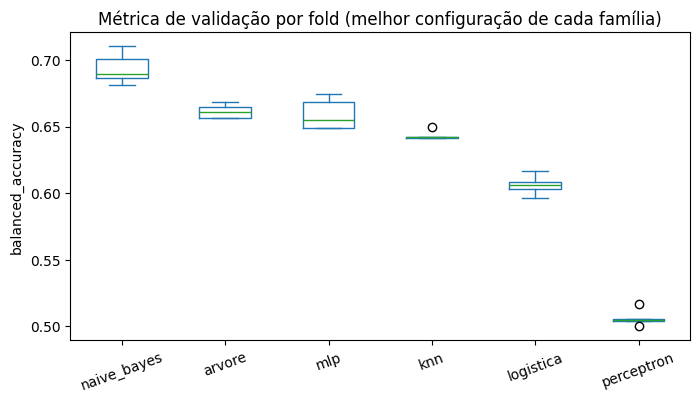

In [12]:
# Tabela de validação cruzada (pronto)
tabela_cv = am.cv_summary(buscas)
display(tabela_cv)
tabela_cv.to_csv(os.path.join(PASTA, "tabela_cv.csv"))

folds = am.cv_fold_scores(buscas)
ax = folds[tabela_cv.index].plot(kind="box", figsize=(8, 4), rot=20)
ax.set_ylabel(SCORING)
ax.set_title("Métrica de validação por fold (melhor configuração de cada família)")
plt.show()

In [13]:
# TODO (dupla): família campeã, escolhida pela validação cruzada (nunca pelo teste).
CAMPEAO = tabela_cv.index[0]  # TODO: mantenham ou justifiquem outra escolha (ex.: empate dentro de 1 EP e modelo mais simples)
print("Campeão pela validação cruzada:", CAMPEAO)

Campeão pela validação cruzada: naive_bayes


*Leitura da tabela e justificativa do campeão:*
O Naive Bayes apresentou a maior acurácia balanceada média na validação
cruzada: 0,6937, com desvio padrão de 0,0103 e erro padrão de 0,0046.
Por esse critério, foi escolhido como campeão geral provisório,
exclusivamente com base no desenvolvimento.

A árvore obteve 0,6615 e a MLP, 0,6592. A diferença de 0,0023 entre
essas famílias é pequena em relação à variabilidade entre folds,
não permitindo afirmar uma superioridade clara da árvore.

O Naive Bayes apresentou baixo custo computacional em comparação
com a MLP. Os tempos desta execução estão registrados na coluna
tempo_s da tabela. Esses valores correspondem às buscas apresentadas,
sem somar as buscas exploratórias anteriores, e podem variar conforme
os recursos disponíveis no Colab.

O kNN apresentou desempenho de treino próximo de 1, mas validação de
0,6435. Como a configuração selecionada utiliza weights="distance",
cada observação de treino pode ser seu próprio vizinho, favorecendo
um resultado de treino quase perfeito. Essa lacuna exige interpretação
cuidadosa no estudo de overfitting.

A regressão logística e o Perceptron apresentaram resultados inferiores
nas configurações investigadas. O Perceptron obteve 0,5063, próximo da
referência de 0,5 de acurácia balanceada para um classificador que prevê
sempre a mesma classe. Isso não permite concluir, sem examinar suas
predições, que ele esteja necessariamente prevendo apenas uma classe.

As conclusões se limitam aos dados, ao pré-processamento e às
configurações avaliadas. O conjunto de teste ainda não foi utilizado
nesta etapa.

## 6. Estudo de overfitting: viés, variância e complexidade

### 6.1 Lacuna treino-validação por família

Para a melhor configuração de cada família, comparamos a métrica no treino e na validação de cada fold. Lacuna grande sugere **variância** alta (o modelo se ajusta a particularidades do treino); desempenho baixo nos dois com lacuna pequena sugere **viés** alto (o modelo é simples demais para o problema).


,treino,validacao,lacuna,lacuna_ep,lacuna_relativa
familia,,,,,
knn,0.9988,0.6435,0.3554,0.0014,0.3558
mlp,0.6736,0.6592,0.0144,0.0017,0.0214
arvore,0.6635,0.6615,0.0020,0.0022,0.0030
naive_bayes,0.6953,0.6937,0.0016,0.0048,0.0023
logistica,0.6074,0.6063,0.0010,0.0034,0.0017
perceptron,0.5054,0.5063,-0.0009,0.0009,-0.0018


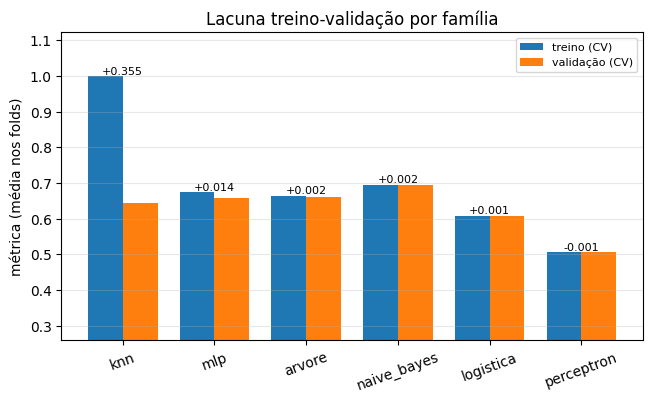

In [14]:
# Lacuna treino-validação (pronto)
lacunas = am.generalization_gap(buscas)
display(lacunas)
am.plot_generalization_gap(lacunas)
plt.show()

*Leitura da lacuna treino-validação:*
O kNN apresentou a maior lacuna treino-validação: aproximadamente
0,3554. Entretanto, a ponderação por distância favorece um desempenho
de treino quase perfeito, pois cada observação pode ser seu próprio
vizinho. Portanto, essa lacuna não deve ser interpretada isoladamente
como uma medida direta da variância.

A MLP apresentou uma lacuna de 0,0144, indicando algum ajuste adicional
ao treino, mas sem uma diferença tão acentuada quanto a observada no kNN.

A árvore e o Naive Bayes apresentaram lacunas pequenas, de aproximadamente
0,0020 e 0,0016, respectivamente. O Naive Bayes combinou uma lacuna
pequena com a maior média de validação entre as famílias investigadas.

A regressão logística e o Perceptron tiveram desempenho relativamente
baixo tanto no treino quanto na validação. Esse comportamento é
compatível com subajuste nas configurações avaliadas, embora a lacuna
sozinha não permita determinar a causa do desempenho limitado.

A pequena lacuna negativa do Perceptron não indica um erro: a validação
pode apresentar desempenho ligeiramente superior ao treino devido
à variação entre as amostras dos folds.

### 6.2 Curvas de validação de complexidade com a regra de 1 erro padrão

Três curvas obrigatórias: profundidade da árvore (`max_depth`), número de vizinhos do kNN (`n_neighbors`) e regularização da MLP (`alpha`). Cada ponto é a média nos mesmos folds, com faixa de mais ou menos 1 erro padrão. Os demais hiperparâmetros ficam nos valores escolhidos na Seção 4.

A regra de 1 EP é uma heurística que favorece modelos mais simples
com desempenho próximo ao melhor observado. Ela não constitui
um teste formal de equivalência estatística.



In [15]:
# TODO (dupla): valores de cada curva (ajustem a faixa ao problema; incluam a região de sub e de sobreajuste).
curvas_cfg = {
    "arvore": ("max_depth", [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, None], "lower"),
    "knn": ("n_neighbors", [1, 3, 5, 7, 11, 15, 21, 31, 51, 81], "higher"),
    "mlp": ("alpha", [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0], "higher"),
}
# Hiperparâmetros fixos de cada curva: por padrão, os melhores da busca (exceto o que varia).
fixos = {familia: buscas[familia] for familia in curvas_cfg}
# Exemplo: fixos["knn"] = {**am.best_model_params(buscas["knn"], drop="n_neighbors"), "weights": "uniform"}

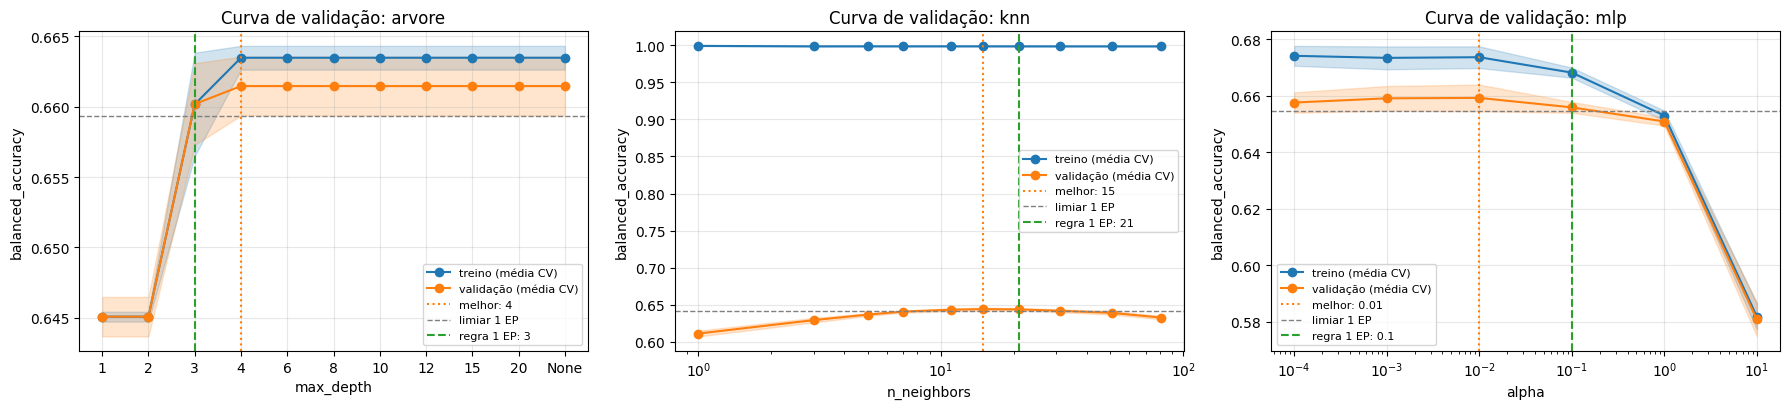

,parametro,melhor_media,regra_1ep,escolhido_na_busca
arvore,max_depth,4,3,5
knn,n_neighbors,15,21,21
mlp,alpha,0.01,0.1,0.01


In [16]:
# Curvas de validação e regra de 1 EP (pronto)
curvas, escolhas = {}, {}
fig, axes = plt.subplots(1, len(curvas_cfg), figsize=(6 * len(curvas_cfg), 4.2))
for ax, (familia, (param, valores, mais_simples)) in zip(np.atleast_1d(axes), curvas_cfg.items()):
    curvas[familia] = am.validation_curve(familia, param, valores, X_dev, y_dev, cv=cv, scoring=SCORING,
                                          fixed_params=fixos[familia], n_jobs=N_JOBS, seed=SEED)
    escolhas[familia] = {
        "parametro": param,
        "melhor_media": am.select_complexity(curvas[familia], rule="max"),
        "regra_1ep": am.select_complexity(curvas[familia], rule="1se", simpler=mais_simples),
        "escolhido_na_busca": am.best_model_params(buscas[familia]).get(param),
    }
    am.plot_validation_curve(curvas[familia], ax=ax, simpler=mais_simples)
plt.tight_layout()
plt.show()
display(pd.DataFrame(escolhas).T)

### 6.3 Leitura por viés e variância e versão que vai ao teste

*Perguntas orientadoras:* Para cada família, o modelo escolhido está na região de viés alto, de variância alta ou próximo do equilíbrio? A regra de 1 EP sugere uma versão mais simples sem perda relevante? Vocês vão levar ao teste a configuração de melhor média ou a da regra de 1 EP? A decisão precisa ser tomada **agora**, antes da Seção 7. Se alguma família vai ao teste na versão da regra de 1 EP, a escolha do campeão geral (`CAMPEAO`) continua válida com a estimativa dessa versão?

*Discussão da dupla:* Na árvore, profundidades 1 e 2 apresentaram desempenho inferior,
compatível com subajuste. A partir da profundidade 4, a curva apresentou
um plateau. Não observamos aumento expressivo da lacuna nas maiores
profundidades, pois min_samples_leaf=400 também limita a complexidade.
A regra de 1 EP selecionou profundidade 3.

No kNN, poucos vizinhos produziram menor desempenho de validação.
A melhor média da curva ocorreu com 15 vizinhos, enquanto a regra
de 1 EP selecionou 21. A curva de treino permaneceu próxima de 1
devido à ponderação por distância. Mais vizinhos representam uma
fronteira de decisão mais suave.

Na MLP, a melhor média ocorreu com alpha=0,01. A regra de 1 EP
selecionou alpha=0,1, aumentando a regularização e reduzindo a lacuna.
Com alpha=10, treino e validação caíram acentuadamente, indicando
subajuste associado à regularização excessiva.

Decidimos adotar as versões da regra de 1 EP para árvore, kNN e MLP.
Para Naive Bayes, regressão logística e Perceptron, mantemos as
configurações de melhor média da busca.

A regra de 1 EP é uma heurística de seleção por simplicidade,
não um teste formal de equivalência estatística. As estimativas de CV
das versões escolhidas serão atualizadas antes da avaliação final.
Todas essas decisões utilizam exclusivamente o desenvolvimento.

In [17]:
# TODO (dupla): versão de cada família que vai ao teste (decidida ANTES de usar o teste).
# Por padrão, o melhor modelo de cada busca, já reajustado no desenvolvimento usado na busca.
campeoes = {
    familia: buscas[familia].best_estimator_
    for familia in am.FAMILIES
}
# Estimativa de CV de cada versão que NÃO for a melhor da busca (usada na tabela CV vs. teste da Seção 7).
estimativas_cv = {}

# Se decidirem adotar a regra de 1 EP em alguma família, reajustem no desenvolvimento e registrem a
# estimativa de CV dessa versão (o ponto correspondente da curva), por exemplo:
# campeoes["arvore"] = am.refit_with(buscas["arvore"], X_dev, y_dev, max_depth=escolhas["arvore"]["regra_1ep"])
# Com subamostra (N_MAX_DEV), usem X_dev_completo, y_dev_completo no lugar de X_dev, y_dev (são iguais quando N_MAX_DEV é None).
# estimativas_cv["arvore"] = am.curve_point(curvas["arvore"], escolhas["arvore"]["regra_1ep"])
# Se a curva fixou outro parâmetro de forma diferente da busca (ex.: weights="uniform" no kNN),
# passem-no também a refit_with, para que o modelo reajustado seja o mesmo avaliado na curva.
# Se usaram subamostra (N_MAX_DEV) e o custo permitir, reajustem no desenvolvimento completo:
# Atenção: a linha abaixo substitui TODOS os campeões pela melhor configuração da busca; se a usarem, apliquem a regra de 1 EP DEPOIS dela, com X_dev_completo, y_dev_completo.
# campeoes = {f: am.refit_with(buscas[f], X_dev_completo, y_dev_completo) for f in am.FAMILIES}


# Versões mais simples escolhidas pela regra de 1 EP.
for familia in ("arvore", "knn", "mlp"):
    parametro = escolhas[familia]["parametro"]
    valor = escolhas[familia]["regra_1ep"]

    # Reajuste no desenvolvimento completo, sem utilizar o teste.
    campeoes[familia] = am.refit_with(
        buscas[familia],
        X_dev_completo,
        y_dev_completo,
        **{parametro: valor}
    )

    estimativas_cv[familia] = am.curve_point(
        curvas[familia],
        valor
    )

# Comparação das versões efetivamente escolhidas.
linhas = []

for familia in am.FAMILIES:
    if familia in estimativas_cv:
        media, ep = estimativas_cv[familia]
        criterio = "Regra de 1 EP"
    else:
        media = tabela_cv.loc[familia, "media_cv"]
        ep = tabela_cv.loc[familia, "ep_cv"]
        criterio = "Melhor média da busca"

    linhas.append({
        "familia": familia,
        "criterio": criterio,
        "media_cv": media,
        "ep_cv": ep
    })

tabela_escolhidos = (
    pd.DataFrame(linhas)
    .set_index("familia")
    .sort_values("media_cv", ascending=False)
)

display(tabela_escolhidos)

CAMPEAO = tabela_escolhidos.index[0]
print("Campeão geral escolhido antes do teste:", CAMPEAO)

print("\nConfigurações escolhidas pela regra de 1 EP:")
for familia in ("arvore", "knn", "mlp"):
    parametro = escolhas[familia]["parametro"]
    valor = campeoes[familia].named_steps["model"].get_params()[parametro]
    print(f"{familia}: {parametro} = {valor}")

print("\nNenhuma avaliação no teste foi realizada nesta célula.")

,criterio,media_cv,ep_cv
familia,,,
naive_bayes,Melhor média da busca,0.6937,0.0046
arvore,Regra de 1 EP,0.6602,0.0029
mlp,Regra de 1 EP,0.6558,0.0019
knn,Regra de 1 EP,0.6435,0.0014
logistica,Melhor média da busca,0.6063,0.0029
perceptron,Melhor média da busca,0.5063,0.0026


Campeão geral escolhido antes do teste: naive_bayes

Configurações escolhidas pela regra de 1 EP:
arvore: max_depth = 3
knn: n_neighbors = 21
mlp: alpha = 0.1

Nenhuma avaliação no teste foi realizada nesta célula.


### 6.4 Busca da extensão bônus antes da avaliação final

A busca do LightGBM é executada aqui para que todas as decisões
sejam concluídas antes da avaliação no teste. A justificativa
e a discussão da extensão estão na Seção 10.

In [18]:
# TODO (dupla, opcional): ativem para executar a extensão bônus.
EXECUTAR_EXTENSAO = True

GRADE_EXTENSAO = {
    "model__num_leaves": [2, 3, 5, 7, 15, 31, 63],
    "model__learning_rate": [0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
}

In [19]:
# Extensão bônus no mesmo protocolo (pronto; só executa se EXECUTAR_EXTENSAO = True)
# Extensão bônus: somente desenvolvimento.
# Esta célula NÃO avalia o conjunto de teste.

if EXECUTAR_EXTENSAO:
    busca_ext = am.cv_search(
        "lightgbm",
        X_dev,
        y_dev,
        grid=GRADE_EXTENSAO,
        cv=cv,
        scoring=SCORING,
        n_jobs=N_JOBS,
        seed=SEED,
        prep_kwargs=PREP_KWARGS
    )

    buscas_com_ext = {
        **buscas,
        "lightgbm": busca_ext
    }

    print("Melhores parâmetros do LightGBM:")
    print(busca_ext.best_params_)

    print("\nComparação das buscas por validação cruzada:")
    display(am.cv_summary(buscas_com_ext))

    print("\nLacuna treino-validação:")
    display(am.generalization_gap(buscas_com_ext))

    # Comparação com as versões já selecionadas na Seção 6.3.
    resumo_ext = am.cv_summary({"lightgbm": busca_ext})

    tabela_com_bonus = tabela_escolhidos.copy()
    tabela_com_bonus.loc["lightgbm"] = {
        "criterio": "Melhor média da busca",
        "media_cv": resumo_ext.loc["lightgbm", "media_cv"],
        "ep_cv": resumo_ext.loc["lightgbm", "ep_cv"]
    }

    tabela_com_bonus = tabela_com_bonus.sort_values(
        "media_cv",
        ascending=False
    )

    print("\nComparação com as versões selecionadas das seis famílias:")
    display(tabela_com_bonus)

    print("\nO conjunto de teste não foi utilizado.")

else:
    print("Extensão bônus não executada.")

Melhores parâmetros do LightGBM:
{'model__learning_rate': 0.2, 'model__num_leaves': 7}

Comparação das buscas por validação cruzada:


,metrica,media_cv,dp_cv,ep_cv,media_treino,melhores_parametros,n_config,tempo_s
familia,,,,,,,,
naive_bayes,balanced_accuracy,0.6937,0.0103,0.0046,0.6953,{'var_smoothing': 0.1},7,9.3
arvore,balanced_accuracy,0.6615,0.0047,0.0021,0.6635,"{'max_depth': 5, 'min_samples_leaf': 400}",63,156.7
lightgbm,balanced_accuracy,0.6605,0.0053,0.0024,0.6856,"{'learning_rate': 0.2, 'num_leaves': 7}",42,220.9
mlp,balanced_accuracy,0.6592,0.0105,0.0047,0.6736,"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}",12,488.3
knn,balanced_accuracy,0.6435,0.0031,0.0014,0.9988,"{'n_neighbors': 21, 'weights': 'distance'}",10,185.1
logistica,balanced_accuracy,0.6063,0.0065,0.0029,0.6074,{'C': 100.0},8,13.7
perceptron,balanced_accuracy,0.5063,0.0058,0.0026,0.5054,"{'alpha': 1e-05, 'penalty': 'l2'}",7,13.9



Lacuna treino-validação:


,treino,validacao,lacuna,lacuna_ep,lacuna_relativa
familia,,,,,
knn,0.9988,0.6435,0.3554,0.0014,0.3558
lightgbm,0.6856,0.6605,0.0251,0.0026,0.0367
mlp,0.6736,0.6592,0.0144,0.0017,0.0214
arvore,0.6635,0.6615,0.0020,0.0022,0.0030
naive_bayes,0.6953,0.6937,0.0016,0.0048,0.0023
logistica,0.6074,0.6063,0.0010,0.0034,0.0017
perceptron,0.5054,0.5063,-0.0009,0.0009,-0.0018



Comparação com as versões selecionadas das seis famílias:


,criterio,media_cv,ep_cv
familia,,,
naive_bayes,Melhor média da busca,0.6937,0.0046
lightgbm,Melhor média da busca,0.6605,0.0024
arvore,Regra de 1 EP,0.6602,0.0029
mlp,Regra de 1 EP,0.6558,0.0019
knn,Regra de 1 EP,0.6435,0.0014
logistica,Melhor média da busca,0.6063,0.0029
perceptron,Melhor média da busca,0.5063,0.0026



O conjunto de teste não foi utilizado.


## 7. Avaliação final no teste (uma única vez)

Os campeões de cada família, reajustados no desenvolvimento inteiro (ou na subamostra, se `N_MAX_DEV` foi usado e o reajuste completo não foi viável, o que deve ser declarado), são avaliados no teste da E1 **uma única vez**. A função `am.test_table` registra data e hora em `test_log.csv` e recusa uma segunda execução. Se o notebook for executado de novo, a célula reutiliza a tabela já salva em vez de reavaliar. A avaliação só acontece depois que a dupla escreve a declaração abaixo e define `TESTE_LIBERADO = True`; as predições do campeão ficam gravadas em `predicoes_teste_campeao.csv` e são reutilizadas na Seção 8.

A segunda tabela compara, para a métrica principal, a estimativa da validação cruzada com o resultado no teste (`diferenca_em_ep` expressa a diferença em erros padrão da CV).

*Perguntas orientadoras:* A ordem das famílias no teste confirma a da validação cruzada? As diferenças entre CV e teste são compatíveis com a variabilidade entre folds? Alguma família piorou muito no teste? O que isso indica (variância, mudança de distribuição, teste pequeno)? Lembrem: o teste **não** é usado para trocar o campeão.

**Declaração dos campeões (escrita ANTES de executar a célula do teste):** para cada família, os hiperparâmetros da versão que vai ao teste e o critério (melhor média da CV ou regra de 1 EP); o campeão geral (Seção 5) e a justificativa; se houver opcionais (Seção 10), a grade e o critério da extensão bônus e do LVQ.

*Declaração da dupla:*

### Declaração dos campeões — antes da avaliação no teste

Selecionamos as configurações abaixo exclusivamente por validação
cruzada estratificada com cinco folds no desenvolvimento, utilizando
acurácia balanceada como métrica principal.

| Família | Configuração selecionada | Critério |
|---|---|---|
| Árvore de decisão | max_depth=3; min_samples_leaf=400 | Regra de 1 EP |
| kNN | n_neighbors=21; weights="distance" | Regra de 1 EP |
| Naive Bayes Gaussiano | var_smoothing=0.1 | Melhor média da busca |
| Regressão logística | C=100; demais parâmetros conforme o kit | Melhor média da busca |
| Perceptron calibrado | penalty="l2"; alpha=1e-5; calibração sigmoide com cv=3 | Melhor média da busca |
| MLP | hidden_layer_sizes=(32,); alpha=0.1; early_stopping=False; max_iter=300 | Regra de 1 EP |

O campeão geral é o Naive Bayes, com acurácia balanceada média
de 0,6937 e erro padrão de 0,0046 na validação cruzada.
Ele permanece com a maior média após a atualização das versões
selecionadas pela regra de 1 EP.

Todos os modelos foram ajustados no desenvolvimento completo,
com 25.470 registros, mantendo o pré-processamento dentro dos Pipelines.

O teste contém os mesmos 4.495 registros reservados na Entrega 1.
Seu uso anterior na E1 é reconhecido como limitação, e seus resultados
não foram utilizados para orientar as decisões desta entrega.

Avaliaremos os seis campeões em uma única execução, com registro
em test_log.csv. Nenhum hiperparâmetro, pré-processamento ou campeão
será alterado em função dos resultados do teste.

### Extensão bônus declarada antes do teste

Incluímos o LightGBM como extensão bônus, selecionado pela maior
média de acurácia balanceada na validação cruzada.

A grade final investigou:
- num_leaves: [2, 3, 5, 7, 15, 31, 63];
- learning_rate: [0.02, 0.05, 0.1, 0.2, 0.3, 0.5].

A configuração selecionada foi num_leaves=7, learning_rate=0,2
e n_estimators=200. O modelo foi reajustado no desenvolvimento
completo pela busca, utilizando o mesmo pré-processamento.

Sua média de validação foi de 0,6605, com erro padrão de 0,0024.
O campeão geral permanece o Naive Bayes, inclusive considerando
a extensão.

A avaliação do LightGBM será realizada uma única vez no mesmo
teste, com registro próprio em test_log_extensao.csv.
Não incluímos LVQ nesta entrega.

In [20]:
# TODO (dupla): liberação do teste. Mudem para True SOMENTE depois de escrever a declaração dos campeões acima.
# Enquanto for False, "Reiniciar e executar tudo" para na célula seguinte, sem tocar no teste.
TESTE_LIBERADO = True

In [21]:
# Avaliação no teste, uma única vez (pronto)
CAMINHO_LOG = os.path.join(PASTA, "test_log.csv")
CAMINHO_TABELA_TESTE = os.path.join(PASTA, "tabela_teste.csv")
CAMINHO_PRED_TESTE = os.path.join(PASTA, "predicoes_teste_campeao.csv")

# Trava: sem liberação e sem uso anterior registrado, nada é avaliado no teste.
if not globals().get("TESTE_LIBERADO", False) and not os.path.exists(CAMINHO_LOG):
    raise RuntimeError(
        "Teste ainda não liberado (nada foi avaliado no teste). Escrevam a declaração dos campeões "
        "acima e definam TESTE_LIBERADO = True na célula anterior; até lá, a execução para aqui."
    )

if os.path.exists(CAMINHO_LOG) and os.path.exists(CAMINHO_TABELA_TESTE):
    tabela_teste = pd.read_csv(CAMINHO_TABELA_TESTE, index_col=0)
    print("O teste já foi avaliado; usando a tabela registrada.")
    print("Reexecução: as Seções 7 e 8 só são válidas se os campeões e o CAMPEAO não mudaram "
          "desde a avaliação registrada.")
elif os.path.exists(CAMINHO_LOG):
    # Registro sem tabela (por exemplo, a sessão caiu logo depois da avaliação).
    raise RuntimeError(
        "Há registro de uso do teste, mas a tabela não foi salva. Não reavaliem por conta própria: "
        "informem o professor e declarem o ocorrido na Seção 7. Só com a autorização do professor a "
        "tabela é recriada, com os mesmos campeões, usando force=True em am.test_table (o novo uso "
        "fica registrado como forçado)."
    )
else:
    if N_MAX_DEV is not None:
        print("Atenção: confiram se os campeões foram reajustados no desenvolvimento completo "
              "(X_dev_completo) ou declarem a limitação.")
    tabela_teste = am.test_table(campeoes, X_test, y_test, log_path=CAMINHO_LOG, note="Entrega 2")
    tabela_teste.to_csv(CAMINHO_TABELA_TESTE)
    # Predições do campeão nesta mesma avaliação, reutilizadas na Seção 8.
    pred_campeao = campeoes[CAMPEAO].predict(X_test)
    pd.DataFrame({
        "campeao": CAMPEAO,
        "y_pred": pred_campeao,
        "posicao_classe": pd.Index(campeoes[CAMPEAO].classes_).get_indexer(pred_campeao),
    }, index=X_test.index).to_csv(CAMINHO_PRED_TESTE)

# Evidência do uso único, visível também no PDF da primeira execução.
print("Registro de uso do teste (data e hora):")
display(pd.read_csv(CAMINHO_LOG))
display(tabela_teste)
display(am.compare_cv_test(buscas, tabela_teste, cv_estimates=estimativas_cv))

O teste já foi avaliado; usando a tabela registrada.
Reexecução: as Seções 7 e 8 só são válidas se os campeões e o CAMPEAO não mudaram desde a avaliação registrada.
Registro de uso do teste (data e hora):


,data_hora,execucao,forcada,modelos,n_teste,observacao
0,2026-10-26T18:13:26+00:00,1,False,arvore;knn;naive_bayes;logistica;perceptron;mlp,4495,Entrega 2


,accuracy,balanced_accuracy,f1_macro,auc,log_loss
modelo,,,,,
arvore,0.8200,0.6586,0.6835,0.7237,0.4500
knn,0.8116,0.6424,0.6649,0.7394,0.6414
naive_bayes,0.7546,0.6966,0.6760,0.7421,0.9867
logistica,0.8127,0.6085,0.6271,0.7319,0.4626
perceptron,0.7800,0.5047,0.4489,0.7257,0.4844
mlp,0.8154,0.6509,0.6745,0.7704,0.4354


,metrica,origem_cv,cv_media,cv_ep,teste,diferenca,diferenca_em_ep
familia,,,,,,,
naive_bayes,balanced_accuracy,busca,0.6937,0.0046,0.6966,0.0029,0.6197
arvore,balanced_accuracy,informada,0.6602,0.0029,0.6586,-0.0016,-0.5421
mlp,balanced_accuracy,informada,0.6558,0.0019,0.6509,-0.0049,-2.5737
knn,balanced_accuracy,informada,0.6435,0.0014,0.6424,-0.0011,-0.7731
logistica,balanced_accuracy,busca,0.6063,0.0029,0.6085,0.0022,0.7526
perceptron,balanced_accuracy,busca,0.5063,0.0026,0.5047,-0.0016,-0.6362


*Leitura da avaliação no teste:*
A avaliação final foi realizada uma única vez sobre os 4.495 registros
do teste, conforme o registro apresentado, com execucao=1 e forcada=False.

O Naive Bayes, escolhido antes do teste, apresentou a maior acurácia
balanceada: 0,6966, comparada a 0,6937 na validação cruzada.
A diferença foi de 0,0029, aproximadamente 0,62 erro padrão da CV.
A ordem das seis famílias pela métrica principal foi preservada.

Para árvore, kNN, regressão logística e Perceptron, as diferenças
absolutas entre CV e teste ficaram abaixo de um erro padrão da CV.
A MLP apresentou a maior redução relativa a esse erro padrão:
de 0,6558 para 0,6509, uma queda de 0,0049, ou 0,49 ponto percentual.

Embora essa diferença corresponda a aproximadamente 2,57 erros padrão
da CV, ela não demonstra, isoladamente, sobreajuste ou mudança de
distribuição. O erro padrão entre folds não é um intervalo formal
para o resultado do teste, que também está sujeito à variabilidade
amostral.

Entre as seis famílias obrigatórias, as métricas complementares mostram diferentes aspectos do desempenho.

A árvore apresentou a maior acurácia (0,8200) e o maior F1 macro
(0,6835). A MLP apresentou a maior AUC (0,7704) e o menor log loss
(0,4354).

O Naive Bayes teve acurácia menor (0,7546), apesar de apresentar
a maior acurácia balanceada. Isso evidencia a importância da métrica
definida antes da busca: a acurácia balanceada atribui o mesmo peso
ao recall de cada classe. A análise por classe será apresentada
na Seção 8.

O log loss relativamente elevado do Naive Bayes (0,9867) indica
uma limitação na qualidade das probabilidades previstas, apesar
do melhor resultado na métrica principal.

Mantemos o Naive Bayes como campeão. Nenhuma configuração foi
alterada com base nos resultados do teste.

## 8. Matriz de confusão e erros por classe do campeão

A análise usa as predições do campeão (escolhido na Seção 5) sobre o teste, sem nenhuma nova decisão de modelagem: é a mesma avaliação única da Seção 7, olhada classe a classe.

*Perguntas orientadoras:* Quais classes são mais confundidas entre si? O recall da classe minoritária é aceitável para o uso pretendido? Os erros fazem sentido à luz da exploração da E1 (classes parecidas, atributos pouco informativos, poucos exemplos)? Que dado ou atributo adicional poderia reduzir esses erros?

previsto,0,1
real,,
0,2803,698
1,405,589


,suporte,recall,precisao,f1
classe,,,,
0,3501,0.8006,0.8738,0.8356
1,994,0.5926,0.4577,0.5164


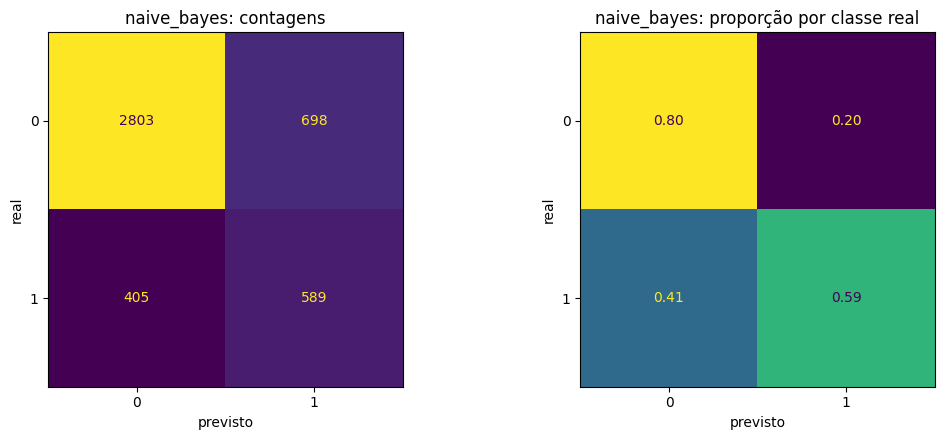

In [22]:
# Erros por classe do campeão (pronto)
modelo_campeao = campeoes[CAMPEAO]
classes = modelo_campeao.classes_
nome_campeao = CAMPEAO
if os.path.exists(CAMINHO_PRED_TESTE):
    # Predições gravadas na avaliação única da Seção 7: nenhuma nova predição no teste.
    registradas = pd.read_csv(CAMINHO_PRED_TESTE, index_col=0)
    y_pred = classes[registradas["posicao_classe"].to_numpy()]
    nome_campeao = registradas["campeao"].iloc[0]
    if nome_campeao != CAMPEAO:
        print(f"Atenção: CAMPEAO ({CAMPEAO}) difere do campeão registrado na avaliação única "
              f"({nome_campeao}); a análise usa o registrado. Trocar o campeão depois do teste não é permitido.")
else:
    y_pred = modelo_campeao.predict(X_test)

display(am.confusion_table(y_test, y_pred, classes=classes))
display(am.recall_per_class(y_test, y_pred, classes=classes))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
am.plot_confusion(y_test, y_pred, classes=classes, normalize=None, ax=axes[0], title=f"{nome_campeao}: contagens")
am.plot_confusion(y_test, y_pred, classes=classes, normalize="true", ax=axes[1], title=f"{nome_campeao}: proporção por classe real")
plt.tight_layout()
plt.show()

*Análise dos erros:*

A matriz de confusão apresenta as classes reais nas linhas e as
classes previstas nas colunas. A classe 1 representa inadimplência.

Dos 994 clientes inadimplentes, o modelo identificou corretamente
589 e classificou incorretamente 405 como não inadimplentes.
O recall da classe 1 foi de 59,26%: aproximadamente 40,74% dos
casos de inadimplência não foram identificados.

Dos 3.501 clientes não inadimplentes, 2.803 foram classificados
corretamente e 698 foram classificados como inadimplentes.
O recall da classe 0 foi de 80,06%.

A média dos recalls das duas classes corresponde à acurácia
balanceada de aproximadamente 69,66%, consistente com a Seção 7.

A precisão da classe 1 foi de 45,77%. Portanto, entre os clientes
classificados como inadimplentes, menos da metade efetivamente
pertencia a essa classe.

Os dois tipos de erro têm consequências distintas. Os falsos negativos
(405) representam riscos de inadimplência que o modelo não sinalizou.
Os falsos positivos (698) poderiam levar a análises adicionais ou
restrições de crédito para clientes que não ficaram inadimplentes.

Embora tenha obtido a maior acurácia balanceada entre as configurações
avaliadas, o campeão ainda apresenta limitações relevantes nas duas
classes. Os resultados não justificam seu uso isolado para decisões
automáticas de crédito. A aceitabilidade desses erros depende dos
custos e dos critérios da aplicação, não definidos neste estudo.

Como trabalho futuro, seria possível investigar atributos adicionais
e critérios de decisão sensíveis aos custos dos erros, utilizando
dados de desenvolvimento e uma avaliação independente.
Nenhum ajuste foi realizado a partir destes resultados de teste.

## 9. Conclusões e próximos passos

Os resultados indicam que os atributos demográficos e o histórico
financeiro permitem identificar parte do risco de inadimplência,
mas com limitações importantes.

O Naive Bayes foi escolhido exclusivamente pela validação cruzada,
com acurácia balanceada média de 0,6937. No teste, obteve 0,6966,
mantendo a maior pontuação nessa métrica entre as seis famílias
obrigatórias e a extensão LightGBM.

O campeão identificou 589 dos 994 clientes inadimplentes,
com recall de 59,26%. Entretanto, deixou de identificar 405
inadimplentes e classificou incorretamente 698 clientes
não inadimplentes como inadimplentes. Portanto, os resultados
não justificam seu uso isolado em decisões automáticas de crédito.

A comparação evidenciou diferenças entre os critérios de avaliação.
O LightGBM apresentou os melhores valores observados de acurácia,
AUC e log loss, enquanto o Naive Bayes apresentou a maior
acurácia balanceada. A escolha do campeão foi mantida conforme
a métrica definida antes das buscas.

No estudo de viés e variância, a árvore e o Naive Bayes apresentaram
pequenas lacunas treino-validação. A regressão logística e o
Perceptron apresentaram desempenho limitado em ambos os conjuntos,
compatível com subajuste nas configurações investigadas.
A interpretação do kNN exige cuidado, pois a ponderação por
distância favorece desempenho quase perfeito no próprio treino.
A MLP apresentou uma lacuna moderada, reduzida com maior regularização.

A regra de 1 erro padrão permitiu selecionar versões mais simples
da árvore e da MLP, com desempenho próximo ao melhor observado.
No kNN, indicou 21 vizinhos, coincidindo com a escolha da busca.

As hipóteses dos modelos também limitam a interpretação. Os históricos
financeiros podem apresentar dependências entre atributos, enquanto
o Naive Bayes assume independência condicional. Além disso, a hipótese
gaussiana não descreve diretamente atributos codificados por one-hot.
Seu bom resultado neste experimento não comprova essas hipóteses.

Entre as limitações estão o uso anterior do teste na E1 como
diagnóstico preliminar, o tamanho finito do teste, as grades
limitadas de hiperparâmetros e a seleção baseada nos mesmos folds
de CV. Não utilizamos subamostragem do desenvolvimento.
As conclusões se restringem a esta base histórica de clientes
de Taiwan e não demonstram generalização para outras populações
ou períodos.

Como próximos passos, recomendamos investigar dados mais recentes,
validação temporal ou externa, atributos adicionais e avaliação
dos custos de falsos positivos e falsos negativos. A calibração
das probabilidades e a escolha de limiares poderiam ser estudadas
exclusivamente em dados de desenvolvimento, com uma nova avaliação
independente. Nenhum desses ajustes foi realizado após observar
o teste desta entrega.

## 10. Opcionais

### 10.1 LVQ (opcional, sem pontos extras)

A dupla pode incluir a implementação do LVQ feita na E1, desde que siga o **mesmo protocolo**: a classe deve seguir a interface do scikit-learn (herdar de `BaseEstimator` e `ClassifierMixin`, receber os hiperparâmetros no `__init__`, implementar `fit` e `predict`, e expor `classes_`), para poder entrar no Pipeline e na mesma validação cruzada. Sem `predict_proba`, AUC e log loss ficam em branco na tabela. Sem `predict_proba`, o LVQ só pode entrar na busca quando a métrica principal se baseia na classe prevista (acurácia, acurácia balanceada ou F1 macro). A grade e o critério do LVQ são declarados na Seção 7, antes do teste; a avaliação no teste usa um registro próprio (outro `log_path`, por exemplo `test_log_lvq.csv`), também usado uma única vez.

Não incluímos LVQ nesta entrega. Como extensão opcional, investigamos
o LightGBM, apresentado a seguir.

### 10.2 Extensão bônus (opcional, até 0,5 ponto, nota limitada a 10)

Um modelo além do curso (por exemplo, LightGBM, já instalado no Colab, ou um modelo tabular recente), avaliado **no mesmo protocolo**: mesmos folds, mesma métrica, grade justificada, pré-processamento no Pipeline e avaliação no teste uma única vez (com registro próprio, `test_log_extensao.csv`). A grade e o critério da extensão são declarados na Seção 7, antes do teste, e não são alterados depois de ver os resultados do teste. A comparação com as famílias do curso deve se apoiar primeiro na validação cruzada. A avaliação da extensão no teste também espera `TESTE_LIBERADO = True` (Seção 7): antes disso, a célula faz só a validação cruzada.

*Perguntas orientadoras:* O ganho em relação ao melhor modelo do curso supera o erro padrão da CV? A lacuna treino-validação é maior ou menor? O custo computacional e a perda de interpretabilidade se justificam?

### Justificativa da extensão bônus

Incluímos o LightGBM como modelo adicional baseado em boosting de árvores.
Diferentemente de uma árvore isolada, o método combina árvores construídas
sequencialmente para melhorar as previsões.

Investigamos num_leaves, que controla o número máximo de folhas por
árvore, e learning_rate, que controla a contribuição de cada etapa.
Mantivemos n_estimators=200, conforme a configuração do kit.

A extensão utilizou os mesmos dados de desenvolvimento, os mesmos
cinco folds, a mesma métrica principal e o pré-processamento dentro
do Pipeline, com as mesmas colunas categóricas.

A comparação considerou o desempenho de validação, a variabilidade,
a lacuna treino-validação e o custo computacional.

Na busca inicial, o LightGBM selecionou num_leaves=7 e
learning_rate=0,2, ambos nas bordas das faixas investigadas.
Por isso, ampliamos a busca para árvores com menos folhas
e taxas de aprendizagem maiores, mantendo n_estimators=200,
os mesmos folds, a métrica e o pré-processamento.

A grade final investigou num_leaves em [2, 3, 5, 7, 15, 31, 63]
e learning_rate em [0.02, 0.05, 0.1, 0.2, 0.3, 0.5].
A configuração selecionada permaneceu num_leaves=7 e
learning_rate=0,2, agora no interior das faixas investigadas.

Todas essas decisões foram tomadas exclusivamente com base
na validação cruzada no desenvolvimento. O teste permaneceu
reservado até a definição da configuração e do critério da extensão,
declarados na Seção 7 antes da avaliação única, com registro próprio.

Nenhum hiperparâmetro foi alterado após observar os resultados do teste.

In [23]:
CAMINHO_LOG_EXT = os.path.join(PASTA, "test_log_extensao.csv")
CAMINHO_TABELA_EXT = os.path.join(PASTA, "tabela_teste_extensao.csv")

if (
    os.path.exists(CAMINHO_LOG_EXT)
    and os.path.exists(CAMINHO_TABELA_EXT)
):
    tabela_ext = pd.read_csv(CAMINHO_TABELA_EXT, index_col=0)
    print("Reutilizando os resultados registrados da extensão.")

elif os.path.exists(CAMINHO_LOG_EXT):
    raise RuntimeError(
        "Há registro do teste da extensão, mas falta a tabela. "
        "Não reavaliem: informem o professor."
    )

elif not TESTE_LIBERADO:
    raise RuntimeError("Teste ainda não liberado.")

else:
    tabela_ext = am.test_table(
        {"lightgbm": busca_ext.best_estimator_},
        X_test,
        y_test,
        log_path=CAMINHO_LOG_EXT,
        note="Extensão bônus LightGBM — Entrega 2"
    )
    tabela_ext.to_csv(CAMINHO_TABELA_EXT)

display(pd.read_csv(CAMINHO_LOG_EXT))
display(tabela_ext)

display(am.compare_cv_test(
    {"lightgbm": busca_ext},
    tabela_ext
))

Reutilizando os resultados registrados da extensão.


,data_hora,execucao,forcada,modelos,n_teste,observacao
0,2026-10-26T18:16:59+00:00,1,False,lightgbm,4495,Extensão bônus LightGBM — Entrega 2


,accuracy,balanced_accuracy,f1_macro,auc,log_loss
modelo,,,,,
lightgbm,0.8214,0.6566,0.6823,0.7809,0.4285


,metrica,origem_cv,cv_media,cv_ep,teste,diferenca,diferenca_em_ep
familia,,,,,,,
lightgbm,balanced_accuracy,busca,0.6605,0.0024,0.6566,-0.0039,-1.6317


### Avaliação e discussão da extensão bônus

O LightGBM foi avaliado uma única vez nos mesmos 4.495 registros
de teste, com registro próprio, execucao=1 e forcada=False.

A acurácia balanceada foi de 0,6566, comparada a 0,6605 na validação
cruzada. A redução de 0,0039 corresponde a aproximadamente
0,39 ponto percentual e 1,63 erros padrão da CV. Essa comparação
é descritiva e não constitui um teste estatístico.

Na métrica principal, o LightGBM não superou o Naive Bayes,
que obteve 0,6966 no teste. Entretanto, apresentou a maior
acurácia observada entre os sete modelos (0,8214), a maior AUC
(0,7809) e o menor log loss (0,4285). Seu F1 macro foi de 0,6823.

Esses resultados mostram que a conclusão depende do aspecto
avaliado: o LightGBM apresentou bons resultados de ordenação
do risco e de qualidade das probabilidades, mas não a maior
média dos recalls das classes na regra de classificação utilizada.

Na validação cruzada, sua lacuna treino-validação foi de 0,0251,
maior que a do Naive Bayes e da árvore selecionada pela busca.
A combinação de árvores também exigiu maior tempo de busca
que o Naive Bayes.

Mantemos o Naive Bayes como campeão pela métrica previamente
definida. Nenhum modelo ou hiperparâmetro foi alterado após
a avaliação no teste.

## 11. Declaração de uso de IA (obrigatória)

O GPT-6 Astra foi utilizado para auxiliar na tradução dos conteúdos (alemão/português). Além disso, o Astra foi empregado para ajudar a corrigir erros no código e para obter uma visão geral inicial do problema. Todo o material gerado pelo Astra foi duplamente verificado com o auxílio dos materiais disponibilizados em aula.